# 딥러닝 3일차 (2) — 미분의 개념 · 수치 미분

수업 필기 `수치미분`(직접 작성)과 메모 `딥러닝_노트_수정본` 의 미분 부분을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `딥러닝` 교재8 p.50~52 — 미분의 개념과 딥러닝에서의 필요성 · 수치 미분)

- 손실 함수(MSE · 교차 엔트로피)는 [`loss_functions.ipynb`](./loss_functions.ipynb) 에 있습니다.
- 필기 · 교재에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다. **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:  # 리눅스 · 코랩 : 설치된 한글 폰트가 있으면 사용
    names = {f.name for f in fm.fontManager.ttflist}
    for name in ['NanumGothic', 'Noto Sans CJK KR']:
        if name in names:
            plt.rcParams['font.family'] = name
            break
plt.rcParams['axes.unicode_minus'] = False

In [2]:
import os
import numpy as np
from matplotlib.animation import FuncAnimation, PillowWriter

os.makedirs('./images', exist_ok=True)

## 1. 미분이란 (교재 p.50)

**미분** = $x$ 를 아주 조금 바꿨을 때 $f(x)$ 가 **얼마나 민감하게 변하는지** = **순간 변화율** = 그래프 위 한 점에서의 **접선의 기울기**.

$$f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}$$

- $\dfrac{f(x+h) - f(x)}{h}$ : 두 점을 잇는 직선(할선)의 기울기 = **평균 변화율**
- $h$ 를 0 에 한없이 가깝게 줄이면 두 점이 붙어서 → **접선의 기울기** = 미분값

In [3]:
def f(x):
    return x ** 2

a = 1.0
for h in [1.0, 0.5, 0.1, 0.01, 0.001]:
    slope = (f(a + h) - f(a)) / h
    print(f"h = {h:<6} → 평균 변화율 {slope:.4f}")
print("h → 0  → 접선의 기울기 f'(1) = 2 × 1 = 2")

h = 1.0    → 평균 변화율 3.0000
h = 0.5    → 평균 변화율 2.5000
h = 0.1    → 평균 변화율 2.1000
h = 0.01   → 평균 변화율 2.0100
h = 0.001  → 평균 변화율 2.0010
h → 0  → 접선의 기울기 f'(1) = 2 × 1 = 2


In [4]:
# 🎬 애니메이션 : h 를 줄이면 할선(두 점을 잇는 선)이 접선이 된다 (교재 p.50 그림)
hs = np.concatenate([np.geomspace(2.0, 0.02, 40), np.full(6, 0.02)])
xs = np.linspace(-0.5, 3.5, 300)
fig, ax = plt.subplots(figsize=(6.5, 4.6))

def draw(i):
    ax.clear(); h = hs[i]
    ax.plot(xs, f(xs), color='tab:blue', lw=2, label='y = f(x) = x²')
    ax.plot(xs, 2 * a * (xs - a) + f(a), color='tab:red', lw=1.5, label="접선 (기울기 f'(1) = 2)")
    slope = (f(a + h) - f(a)) / h
    ax.plot(xs, slope * (xs - a) + f(a), '--', color='tab:green', lw=1.8, label=f'할선 (평균 변화율 {slope:.3f})')
    ax.plot([a, a + h], [f(a), f(a + h)], 'o', color='k', ms=6)
    ax.annotate('', xy=(a + h, f(a) - 0.6), xytext=(a, f(a) - 0.6), arrowprops=dict(arrowstyle='<->'))
    ax.text(a + h / 2, f(a) - 1.2, f'h = {h:.2f}', ha='center')
    ax.set_xlim(-0.5, 3.5); ax.set_ylim(-2, 10); ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=9)
    ax.set_title('h → 0 : 평균 변화율 → 순간 변화율(미분)')

ani = FuncAnimation(fig, draw, frames=len(hs), interval=120)
ani.save('./images/anim_03_secant_to_tangent.gif', writer=PillowWriter(fps=8), dpi=72)
plt.close()
print("저장 : ./images/anim_03_secant_to_tangent.gif")

저장 : ./images/anim_03_secant_to_tangent.gif


![할선이 접선이 되는 애니메이션](./images/anim_03_secant_to_tangent.gif)

🎬 $x = 1$ 과 $x = 1 + h$ 두 점을 잇는 초록 점선(할선)의 기울기는 $h = 2$ 일 때 4 지만, $h$ 를 0.02 까지 줄이면 2.02 → 빨간 **접선**(기울기 2)과 거의 겹친다.

## 2. 딥러닝에서 미분이 필요한 이유 (교재 p.51)

학습 = 손실 $L$ 을 0 에 가깝게 만드는 가중치 $W$ 찾기. 이때 **"$W$ 를 아주 조금 바꾸면 손실이 늘까, 줄까?"** 를 알려 주는 것이 미분값 $\dfrac{dL}{dW}$ (기울기) 다.

| 기울기 $\dfrac{dL}{dW}$ | 뜻 | 가중치를 |
|---|---|---|
| **양수 (+)** | $W$ 를 키우면 손실이 **늘어난다** | **줄인다 (−)** |
| **음수 (−)** | $W$ 를 키우면 손실이 **줄어든다** | **키운다 (+)** |
| **0** | 바닥(최솟값) | 그대로 |

→ 항상 **기울기의 반대 방향**으로 움직인다.

> ⚠️ 헷갈리지 않기 : 예측식 $y = wx$ 의 $w$ 도 '직선의 기울기' 지만, 학습에서 말하는 기울기는 **손실 곡선 $L(w)$ 의 접선 기울기** $dL/dw$ 다.

데이터로 확인 — 정답이 $t = 2x$ 인 데이터에 $y = wx$ 를 맞출 때, MSE 손실을 $w$ 에 대한 함수로 그리면 **포물선**(교재 p.51 그림)이다.

In [5]:
x_data = np.array([1.0, 2.0, 3.0, 4.0])
t_data = 2 * x_data                          # 정답 : 가중치 2 가 정답

def loss(w):
    y = w * x_data                           # 예측 (편향 없이)
    return np.mean((y - t_data) ** 2)        # MSE

for w in [0.0, 1.0, 2.0, 3.0, 4.0]:
    print(f"w = {w} → 손실 {loss(w):5.2f}")
print("→ w = 2 에서 손실 0 (최솟값), 멀어질수록 손실이 커지는 포물선")

w = 0.0 → 손실 30.00
w = 1.0 → 손실  7.50
w = 2.0 → 손실  0.00
w = 3.0 → 손실  7.50
w = 4.0 → 손실 30.00
→ w = 2 에서 손실 0 (최솟값), 멀어질수록 손실이 커지는 포물선


## 3. 해석적 미분 vs 수치 미분 (교재 p.52)

| | 해석적 미분 | 수치 미분 |
|---|---|---|
| 방법 | 공식으로 ($x^2 \to 2x$) | 아주 작은 $h$ 를 직접 넣어 **근사** |
| 정확도 | 오차 없음 | 아주 작은 오차 |
| 장점 | 정확 · 한 번에 계산 | 함수 모양을 몰라도 계산 가능 |

**중앙 차분** — $x$ 의 **양쪽**으로 $h$ 만큼 움직여서 기울기를 구한다 (한쪽만 보는 전방 차분보다 정확하다).

$$f'(x) \approx \frac{f(x+h) - f(x-h)}{2h} \qquad (h = 0.0001 \text{ 정도})$$

In [6]:
# 필기 `수치미분` 정리 — 함수를 '인자로' 받아서 어떤 함수든 미분할 수 있다
def numerical_diff(f, x, h=1e-4):
    """중앙 차분으로 f 의 x 에서의 기울기를 근사한다"""
    return (f(x + h) - f(x - h)) / (2 * h)

def func(x):
    return x ** 2

target_x = 3.0
analytic = 2 * target_x                       # 해석적 미분 : f'(x) = 2x
numeric = numerical_diff(func, target_x)      # 수치 미분

print("미분할 지점 x :", target_x)
print("해석적 미분   :", analytic)
print("수치 미분     :", numeric)
print("차이          :", abs(numeric - analytic))

미분할 지점 x : 3.0
해석적 미분   : 6.0
수치 미분     : 6.000000000012662
차이          : 1.2661871551244985e-11


수치 미분 결과가 정확히 6 이 아니라 **6.000000000012…** 인 이유 — 컴퓨터는 소수를 2진수로 저장해서 3.0001 같은 수를 **정확히 표현하지 못한다**(부동소수점 반올림 오차). 수학적으로는 $x^2$ 의 중앙 차분이 정확히 $2x$ 다:

$$\frac{(x+h)^2 - (x-h)^2}{2h} = \frac{4xh}{2h} = 2x$$

In [7]:
print("0.1 + 0.2 =", 0.1 + 0.2, " ← 파이썬도 소수 계산에 아주 작은 오차가 있다")
print("3.0001 ** 2 =", 3.0001 ** 2, " (수학적으로는 9.00060001)")

0.1 + 0.2 = 0.30000000000000004  ← 파이썬도 소수 계산에 아주 작은 오차가 있다
3.0001 ** 2 = 9.000600010000001  (수학적으로는 9.00060001)


In [8]:
# 전방 차분 vs 중앙 차분, 그리고 h 가 너무 작으면?
def forward_diff(f, x, h=1e-4):
    return (f(x + h) - f(x)) / h

print(f"{'h':>8} | {'전방 차분 오차':>14} | {'중앙 차분 오차':>14}")
for h in [1e-1, 1e-2, 1e-4, 1e-8, 1e-12, 1e-15]:
    ef = abs(forward_diff(func, 3.0, h) - 6)
    ec = abs(numerical_diff(func, 3.0, h) - 6)
    print(f"{h:>8.0e} | {ef:>14.2e} | {ec:>14.2e}")

print("\nh = 1e-50 :", numerical_diff(func, 3.0, 1e-50), " ← 3 + 1e-50 이 그냥 3 이 되어 기울기 0")
print("float32 에서 3 + 1e-50 == 3 ?", np.float32(3.0) + np.float32(1e-50) == np.float32(3.0))

       h |       전방 차분 오차 |       중앙 차분 오차
   1e-01 |       1.00e-01 |       5.33e-15
   1e-02 |       1.00e-02 |       1.28e-13
   1e-04 |       1.00e-04 |       1.27e-11
   1e-08 |       3.65e-08 |       3.65e-08
   1e-12 |       5.33e-04 |       5.33e-04
   1e-15 |       6.71e-01 |       6.71e-01

h = 1e-50 : 0.0  ← 3 + 1e-50 이 그냥 3 이 되어 기울기 0
float32 에서 3 + 1e-50 == 3 ? True


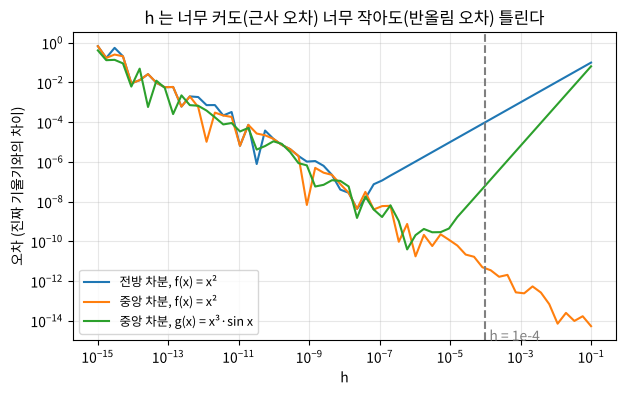

In [9]:
hs_plot = np.geomspace(1e-15, 1e-1, 60)
err_f = [abs(forward_diff(func, 3.0, h) - 6) + 1e-17 for h in hs_plot]
err_c = [abs(numerical_diff(func, 3.0, h) - 6) + 1e-17 for h in hs_plot]

g = lambda x: np.sin(x) * x ** 3             # 공식이 복잡한 함수에서도 확인
true_g = np.cos(2.0) * 8 + np.sin(2.0) * 12
err_g = [abs(numerical_diff(g, 2.0, h) - true_g) + 1e-17 for h in hs_plot]

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(hs_plot, err_f, label='전방 차분, f(x) = x²')
ax.loglog(hs_plot, err_c, label='중앙 차분, f(x) = x²')
ax.loglog(hs_plot, err_g, label='중앙 차분, g(x) = x³·sin x')
ax.axvline(1e-4, color='gray', ls='--'); ax.text(1.3e-4, 1e-15, 'h = 1e-4', color='gray')
ax.set_xlabel('h'); ax.set_ylabel('오차 (진짜 기울기와의 차이)'); ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=9)
ax.set_title('h 는 너무 커도(근사 오차) 너무 작아도(반올림 오차) 틀린다')
plt.show()

- $h$ 가 **너무 크면** : 할선이 접선과 달라서 틀린다(근사 오차) — 전방 차분이 더 크게 틀린다.
- $h$ 가 **너무 작으면** : 컴퓨터의 반올림 오차가 커진다. $h = 10^{-50}$ 이면 $3 + h$ 가 그냥 3 이 되어 기울기가 **0**.
- 그래서 $h = 10^{-4}$ 정도 + **중앙 차분**을 쓴다. ($x^2$ 은 중앙 차분이 수학적으로 정확해서 오차가 반올림 오차뿐이다.)

> **📝 고친 부분** (필기 `수치미분`)
> - 함수 이름 `number_diff` → **`numerical_diff`** (수치 미분 = numerical differentiation)
> - 주석 `# x: 목표 지정` → 목표 **지점**, `# 해석적 미분 df/dx = 2x)` → 괄호 짝 `(df/dx = 2x)`
> - `h = 1/10000` 을 함수 안에 고정 → 인자 `h=1e-4` 로 빼서 바꿔 볼 수 있게
> - 결과 `6.000000000012662` 는 코드 오류가 아니라 **부동소수점 반올림 오차**

## 4. 손실 함수를 수치 미분하기 — 가중치를 어느 쪽으로?

2절의 손실 함수 $L(w)$ 를 `numerical_diff` 에 그대로 넣으면 **공식을 몰라도** 기울기가 나온다. (MSE 를 직접 미분하면 $\dfrac{dL}{dw} = \dfrac{2}{n}\sum (wx - t)\,x$)

In [10]:
def loss_grad_formula(w):                    # 해석적 미분 (확인용)
    return np.mean(2 * (w * x_data - t_data) * x_data)

for w in [0.5, 1.5, 2.0, 2.5, 3.5]:
    g_num = numerical_diff(loss, w)
    direction = '줄인다 ←' if g_num > 1e-6 else ('키운다 →' if g_num < -1e-6 else '그대로 (최솟값)')
    print(f"w = {w} | 손실 {loss(w):6.3f} | 수치 미분 {g_num:8.4f} | 공식 {loss_grad_formula(w):8.4f} | w 를 {direction}")

w = 0.5 | 손실 16.875 | 수치 미분 -22.5000 | 공식 -22.5000 | w 를 키운다 →
w = 1.5 | 손실  1.875 | 수치 미분  -7.5000 | 공식  -7.5000 | w 를 키운다 →
w = 2.0 | 손실  0.000 | 수치 미분   0.0000 | 공식   0.0000 | w 를 그대로 (최솟값)
w = 2.5 | 손실  1.875 | 수치 미분   7.5000 | 공식   7.5000 | w 를 줄인다 ←
w = 3.5 | 손실 16.875 | 수치 미분  22.5000 | 공식  22.5000 | w 를 줄인다 ←


In [11]:
# 🎬 애니메이션 : 손실 곡선 위의 점과 접선 — 기울기 부호가 '가야 할 방향'을 알려 준다 (교재 p.51 그림)
ws = np.concatenate([np.linspace(0.2, 3.8, 46), np.linspace(3.8, 0.2, 46)])
wgrid = np.linspace(0, 4, 300)
Lgrid = np.array([loss(w) for w in wgrid])
fig, ax = plt.subplots(figsize=(7, 4.6))

def draw(i):
    ax.clear(); w = ws[i]; L = loss(w); g = numerical_diff(loss, w)
    ax.plot(wgrid, Lgrid, color='tab:blue', lw=2, label='손실 L(w) (MSE)')
    span = 0.6
    ax.plot([w - span, w + span], [L - g * span, L + g * span], color='tab:red', lw=2, label='접선')
    ax.plot(w, L, 'o', color='tab:red', ms=9)
    if abs(g) > 0.3:
        step = -0.5 * np.sign(g)
        ax.annotate('', xy=(w + step, L), xytext=(w, L),
                    arrowprops=dict(arrowstyle='->', color='green', lw=2.5))
        msg = f"기울기 {g:+.2f} → w 를 {'줄인다' if g > 0 else '키운다'}"
    else:
        msg = f'기울기 {g:+.2f} ≈ 0 → 최솟값'
    ax.axvline(2, color='gray', ls=':', lw=1); ax.text(2.05, 38, '최솟값 w = 2', color='gray')
    ax.set_xlim(0, 4); ax.set_ylim(-3, 45); ax.set_xlabel('가중치 w'); ax.set_ylabel('손실')
    ax.grid(alpha=0.3); ax.legend(loc='upper right', fontsize=9)
    ax.set_title(f'w = {w:.2f} · ' + msg)

ani = FuncAnimation(fig, draw, frames=len(ws), interval=100)
ani.save('./images/anim_04_loss_slope.gif', writer=PillowWriter(fps=10), dpi=72)
plt.close()
print("저장 : ./images/anim_04_loss_slope.gif")

저장 : ./images/anim_04_loss_slope.gif


![손실 곡선의 기울기 애니메이션](./images/anim_04_loss_slope.gif)

🎬 가중치 $w$ 를 0.2 → 3.8 → 0.2 로 움직이며 손실 곡선의 **접선**(빨강)과 **가야 할 방향**(초록 화살표)을 그렸다. 최솟값(w = 2)의 오른쪽은 기울기 **+** → 왼쪽으로, 왼쪽은 기울기 **−** → 오른쪽으로. 최솟값에서 멀수록 기울기가 크고, 가까워질수록 0 에 가까워진다. 이 방향으로 조금씩 움직이는 방법이 다음 시간의 **경사하강법**이다.

> **📝 고친 부분** (교재 p.52)
> - "수치 미분은 컴퓨터가 고속 처리하기에 **가장 최적화**" → 실제 딥러닝(PyTorch · TensorFlow)은 수치 미분을 쓰지 않는다. 가중치 하나마다 손실을 **2번씩** 다시 계산해야 해서 가중치가 수백만 개면 너무 느리다. 실제로는 **오차역전파(자동 미분)** 로 기울기를 한 번에 구하고, 수치 미분은 그 결과가 맞는지 **검산(gradient check)** 할 때 쓴다.
> - (p.53) "소수점 아래까지 **완벽히** 일치" → 실행하면 6.000000000012… 로 아주 작은 반올림 오차가 있다. $h$ 를 너무 작게 하면 오히려 크게 틀린다(3절).

## 5. 정리

| | 내용 |
|---|---|
| 미분 | 순간 변화율 = **접선의 기울기**, $h \to 0$ 일 때의 평균 변화율 |
| 딥러닝에서 | $dL/dW$ 의 **부호** = 가중치를 움직일 방향의 **반대**, 크기 = 얼마나 가파른지 |
| 수치 미분 | $\dfrac{f(x+h) - f(x-h)}{2h}$, $h \approx 10^{-4}$, 중앙 차분 |
| 한계 | 근사값(반올림 오차) · 가중치마다 계산해야 해서 느림 → 실제 학습은 **오차역전파** |

- 다음 : 가중치가 **여러 개**인 손실 함수 → 하나씩 미분하는 **편미분** · 모아 놓은 **기울기(gradient)** (교재 p.54~) → **경사하강법**으로 가중치 업데이트